# PEEP trial segmentation - testing the choices on real recordings

After the preprocessing layer (notebook 05) every recording is an `EITRecording`: breaths, quality flags, lung mask,
regions and the auxiliary signals (pressures). In a PEEP trial the next step is to split the recording by PEEP level:
which breaths belong to each step, which ones are still in the transition after a change, and the pressures of each
breath that layer 3 needs for compliance. This is layer 2b: still preparation of the data, not measurement (the
clinical indices come in layer 3).

As in notebook 05, each section is a question, what I tried, and what I decided. Functions written here are
prototypes, not fastEIT code.

| § | Question |
|---|----------|
| 1 | Which recordings am I using? |
| 2 | Where can the PEEP of each breath come from, and where do I read it? |
| 3 | How do I find the steps? |
| 4 | Can I also measure the plateau and driving pressure of each breath? |
| 5 | How long is the transition after a PEEP change? |
| 6 | Without a pressure signal, can I find the steps from EELI? |
| 7 | Decisions |

The recordings are not in the repository. Times are seconds from the start of each recording. Pressures are in mbar,
as recorded by the Dräger PressurePod (1 mbar = 1.02 cmH2O).

*Research use only - not a medical device.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal, stats

from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess

TEST_FILES = Path("../src/fasteit/test_files")
FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))
NOMINAL_PEEP = np.arange(16, -1, -2)  # the protocol: 16 to 0 in steps of 2

BLUE, ORANGE, GREEN, GREY, INK = "#3987e5", "#e8730c", "#2a9d6f", "#9a9a9a", "#2b2b2b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})


def event_texts(raw, time):
    """(time in s, text) of every Draeger event marker."""
    frames = raw.frames
    changes = np.flatnonzero(np.diff(frames["event_marker"]) != 0) + 1
    return [(float(time[i]), frames["event_text"][i].split(b"\x00")[0].decode(errors="replace").strip())
            for i in changes]


recordings, events = {}, {}
for path in FILES:
    name = path.stem.replace("PEEP_trial_", "")
    raw = load_data(path)
    recordings[name] = preprocess(raw)
    events[name] = event_texts(raw, recordings[name].time)
list(recordings)

['A_park_bench', 'A_supine', 'B_park_bench', 'B_supine']

## 1. Which recordings am I using?

Four decremental PEEP trials from two patients (A and B), each one supine and in park bench position: PEEP from 16 to
0 in steps of 2, volume-controlled ventilation with an end-inspiratory pause, intubated patients. Each step was
annotated by hand in the Dräger event texts. The airway pressure comes from the PressurePod; the ventilator was not
connected through Medibus.

In [2]:
pd.DataFrame(
    {
        name: {
            "duration (s)": round(rec.time[-1]),
            "breaths": len(rec.breaths),
            "breaths/min": round(60 * len(rec.breaths) / rec.time[-1], 1),
            "valid breaths": int(rec.breaths.is_valid.sum()),
            "annotated events": len(events[name]),
            "auxiliary channels": ", ".join(c for c in rec.aux.columns if c not in ("min_max_flag", "event_marker")),
        }
        for name, rec in recordings.items()
    }
).T

,duration (s),breaths,breaths/min,valid breaths,annotated events,auxiliary channels
A_park_bench,519,98,11.3,95,14,airway_pressure_pod
A_supine,591,131,13.3,127,9,airway_pressure_pod
B_park_bench,600,182,18.2,179,10,airway_pressure_pod
B_supine,600,195,19.5,194,10,airway_pressure_pod


## 2. Where can the PEEP of each breath come from, and where do I read it?

Four possible sources:

- **Medibus `peep`**: the value computed by the ventilator. Not available here (no ventilator connected).
- **Event texts**: written by hand at the bedside. They give the nominal PEEP of each step.
- **Airway pressure (`airway_pressure_pod`)**: the measured pressure, frame by frame.
- **EELI**: it follows the PEEP, but it does not give a pressure value (§6).

### Event texts

In [3]:
pd.DataFrame(
    [(name, round(t, 1), text) for name, items in events.items() for t, text in items],
    columns=["trial", "time (s)", "text"],
).set_index(["trial", "time (s)"])

text
trial        time (s)                           
A_park_bench 5.6              park bench peep 16
             51.3             park bench peep 14
             95.7             park bench peep 14
             102.5                       peep 12
             133.8                              
             136.9                       peep 10
             166.4                              
             169.9                        peep 8
             224.4                        peep 6
             273.2                              
             275.3                        perp 4
             319.1                        perp 2
             356.6                        perp 0
             423.3                 aop prk bench
A_supine     2.1              supine vcv peep 16
             136.1            supine vcv peep 14
             176.9            supine vcv peep 12
             222.7            supine vcv peep 10
             274.1             supine vcv peep 8
             321.5             supine vcv peep 6
             365.2             supine vcv peep 4
             420.5             supine vcv peep 2
             463.2             supine vcv peep 0
B_park_bench 2.0                      pb 16 peep
             72.4                     pb 14 peep
             150.4                    pb 12 peep
             224.0                    pb 10 peep
             282.0                     pb 8 peep
             337.4                     pb 6 peep
             401.7                      pb 4peep
             450.3                     pb 2 peep
             490.3                     pb 0 peep
             547.9             pb airway closure
B_supine     0.9               supine iot 16peep
             98.6             supine iot 14 peep
             156.1            supine iot 12 peep
             206.9            supine iot 10 peep
             252.6             supine iot 8 peep
             295.8             supine iot 6 peep
             346.3             supine iot 4 peep
             406.1             supine iot 2 peep
             462.8             supine iot 0 peep
             494.3     supine iot airway closure

The texts name the steps, but they are not clean: one step annotated twice (A park bench, "peep 14"), events
without text, typing errors ("perp 4"), and the maneuvers at the end of the trial ("aop", "airway closure") in the same
list as the steps. In §3 I check when they were written compared with the real change of pressure.

### Where to read the PEEP of a breath on the pressure curve

The airway pressure at the end of expiration is the applied PEEP (the pressure at the airway opening; intrinsic PEEP
would need an end-expiratory occlusion). I compared three readings:

- the pressure at the start of the EIT breath (the EIT valley);
- the median pressure from 0.8 to 0.3 s before the start of the EIT breath;
- the median pressure in the 0.2 s before the **start of inspiration found on the pressure curve itself**: the last
  minimum before the steepest rise of the pressure, searched from 1 s before to 0.5 s after the start of the EIT
  breath.

In [4]:
def smooth(x, n=5):
    return np.convolve(x, np.ones(n) / n, mode="same")


def inspiration_onsets(paw, fs, eit_starts, search=(1.0, 0.5)):
    """Start of inspiration on the pressure: last minimum before the steepest rise near each EIT start."""
    p = smooth(paw)
    slope = np.gradient(p) * fs
    onsets = []
    for start in eit_starts:
        lo, hi = max(0, start - int(search[0] * fs)), min(len(p) - 1, start + int(search[1] * fs))
        steepest = lo + np.argmax(slope[lo:hi])
        back = max(0, steepest - int(0.5 * fs))
        onsets.append(back + np.argmin(p[back : steepest + 1]))
    return np.array(onsets)


def median_before(paw, fs, frames, first, last=0.0):
    """Median pressure from `first` to `last` seconds before each frame."""
    a, b = int(round(first * fs)), int(round(last * fs))
    return np.array([np.median(paw[f - a : f - b]) if f - a >= 0 else np.nan for f in frames])


readings = {}
for name, rec in recordings.items():
    paw, fs = rec.aux.airway_pressure_pod.to_numpy(), rec.fs
    starts = rec.breaths.start_idx.to_numpy()
    onsets = inspiration_onsets(paw, fs, starts)
    readings[name] = pd.DataFrame({
        "at the EIT valley": paw[starts],
        "0.8-0.3 s before the EIT valley": median_before(paw, fs, starts, 0.8, 0.3),
        "0.2 s before the pressure rise": median_before(paw, fs, onsets, 0.2),
        "onset": onsets,
    })

pd.DataFrame({
    name: {"EIT valley - pressure rise (s, median)": np.median(recordings[name].breaths.start_idx - r.onset)
           / recordings[name].fs}
    for name, r in readings.items()
}).T

,"EIT valley - pressure rise (s, median)"
A_park_bench,0.10
A_supine,0.02
B_park_bench,-0.04
B_supine,0.02


The EIT valley falls at the start of the pressure rise (median within 0.1 s), but there the pressure rises
very quickly, so even a small difference in timing changes the reading. I measured the noise (breath-to-breath
change) and, after finding the steps (§3), the level of each step compared with the protocol.

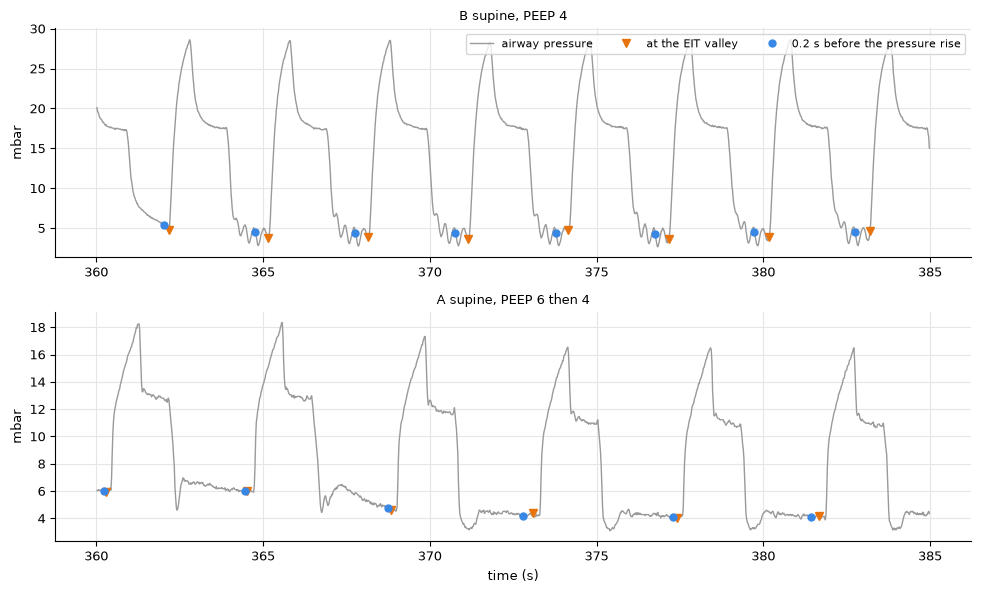

In [5]:
def show_window(ax, name, t0, t1, title):
    rec, r = recordings[name], readings[name]
    t, paw = rec.time, rec.aux.airway_pressure_pod.to_numpy()
    shown = (t >= t0) & (t < t1)
    starts = rec.breaths.start_idx.to_numpy()
    inside = (t[starts] >= t0) & (t[starts] < t1)
    ax.plot(t[shown], paw[shown], color=GREY, lw=1, label="airway pressure")
    ax.plot(t[starts[inside]], paw[starts[inside]], "v", color=ORANGE, ms=6, label="at the EIT valley")
    onsets = r.onset.to_numpy()[inside]
    ax.plot(t[onsets] - 0.1, r["0.2 s before the pressure rise"][inside], "o", color=BLUE, ms=5,
            label="0.2 s before the pressure rise")
    ax.set_title(title, fontsize=9)
    ax.set_ylabel("mbar")


fig, axes = plt.subplots(2, 1, figsize=(10, 6))
show_window(axes[0], "B_supine", 360, 385, "B supine, PEEP 4")
show_window(axes[1], "A_supine", 360, 385, "A supine, PEEP 6 then 4")
axes[0].legend(loc="upper right", ncol=3, fontsize=8)
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

In [6]:
def noise(values):
    """Median breath-to-breath change: small inside a step if the reading is stable."""
    return np.nanmedian(np.abs(np.diff(values)))


pd.DataFrame({name: r.drop(columns="onset").apply(noise) for name, r in readings.items()}).T.round(2).rename_axis(
    "breath-to-breath change (mbar, median)", axis=1)

"breath-to-breath change (mbar, median)",at the EIT valley,0.8-0.3 s before the EIT valley,0.2 s before the pressure rise
A_park_bench,0.15,0.00,0.08
A_supine,0.11,0.04,0.05
B_park_bench,0.08,0.08,0.04
B_supine,0.09,0.05,0.04


## 3. How do I find the steps?

A simple rule on the PEEP of each breath: **a new step starts when three breaths in a row are more than 1 mbar away
from the level of the current step** (half of a 2 mbar step) **and within 1 mbar of each other**. The level of a step
is the median PEEP of its breaths. Requiring three breaths makes a single odd breath (a maneuver, an artifact) unable to
open a step.

In [7]:
def find_steps(peep, threshold=1.0, min_breaths=3, agreement=1.0):
    """Index of the first breath of each step."""
    starts, level, i = [0], peep[0], 1
    while i < len(peep):
        window = peep[i : i + min_breaths]
        new_level = (len(window) == min_breaths and np.all(np.abs(window - level) > threshold)
                     and np.ptp(window) <= agreement)
        if new_level:
            starts.append(i)
            level = np.median(window)
            i += min_breaths
        else:
            level = np.nanmedian(peep[starts[-1] : i + 1])
            i += 1
    return np.array(starts)


def step_levels(peep, step_starts):
    bounds = list(step_starts) + [len(peep)]
    return np.array([np.nanmedian(peep[a:b]) for a, b in zip(bounds[:-1], bounds[1:])])


rows = []
for name, r in readings.items():
    for reading in ("0.8-0.3 s before the EIT valley", "0.2 s before the pressure rise"):
        peep = r[reading].bfill().to_numpy()
        levels = step_levels(peep, find_steps(peep))
        rows.append({"trial": name, "reading": reading, "steps": len(levels),
                     **{f"PEEP {n}": round(level - n, 1) for n, level in zip(NOMINAL_PEEP, levels)}})
pd.DataFrame(rows).set_index(["trial", "reading"]).rename_axis("measured - nominal (mbar)", axis=1)

measured - nominal (mbar)                     steps  PEEP 16  PEEP 14  \
trial        reading                                                    
A_park_bench 0.8-0.3 s before the EIT valley      9      0.0      0.0   
             0.2 s before the pressure rise       9      0.1      0.1   
A_supine     0.8-0.3 s before the EIT valley      9      0.0      0.1   
             0.2 s before the pressure rise       9     -0.0     -0.0   
B_park_bench 0.8-0.3 s before the EIT valley      9      0.5      0.5   
             0.2 s before the pressure rise       9      0.2      0.2   
B_supine     0.8-0.3 s before the EIT valley      9      0.8      0.9   
             0.2 s before the pressure rise       9      0.3      0.4   

measured - nominal (mbar)                     PEEP 12  PEEP 10  PEEP 8  \
trial        reading                                                     
A_park_bench 0.8-0.3 s before the EIT valley      0.0      0.0     0.0   
             0.2 s before the pressure rise       0.0      0.0    -0.0   
A_supine     0.8-0.3 s before the EIT valley      0.2      0.1     0.1   
             0.2 s before the pressure rise       0.0      0.0     0.0   
B_park_bench 0.8-0.3 s before the EIT valley      0.6      0.7     0.7   
             0.2 s before the pressure rise       0.2      0.3     0.3   
B_supine     0.8-0.3 s before the EIT valley      1.0      0.7     0.9   
             0.2 s before the pressure rise       0.5      0.4     0.5   

measured - nominal (mbar)                     PEEP 6  PEEP 4  PEEP 2  PEEP 0  
trial        reading                                                          
A_park_bench 0.8-0.3 s before the EIT valley     0.0     0.0     0.1     0.3  
             0.2 s before the pressure rise      0.0     0.0     0.1     0.3  
A_supine     0.8-0.3 s before the EIT valley     0.2     0.2     0.2     0.6  
             0.2 s before the pressure rise      0.0     0.1     0.2     0.5  
B_park_bench 0.8-0.3 s before the EIT valley     0.6     0.5     0.6     1.2  
             0.2 s before the pressure rise      0.3     0.4     0.5     0.9  
B_supine     0.8-0.3 s before the EIT valley     0.8     0.3     0.9     1.3  
             0.2 s before the pressure rise      0.5     0.5     0.6     1.1

Nine steps in every trial with both readings. In trial A the two readings agree and stay within 0.2 mbar of
the protocol (0.3-0.6 at PEEP 0). In trial B, which breathes faster (about 19/min), the window 0.8-0.3 s before the
EIT valley reads 0.3-1.3 mbar above the protocol, and the reading before the pressure rise only 0.2-0.6 (0.9-1.1 at
PEEP 0): at that rate the earlier window still catches the end of the expiration. **From here on the PEEP of a breath
is the median pressure in the 0.2 s before the pressure rise.**

### How robust are the thresholds?

In [8]:
def breath_peep(name):
    return readings[name]["0.2 s before the pressure rise"].bfill().to_numpy()


pd.DataFrame({
    name: {(threshold, agreement): len(find_steps(breath_peep(name), threshold, 3, agreement))
           for threshold in (0.5, 1.0) for agreement in (0.5, 1.0, 2.0)}
    for name in recordings
}).rename_axis(["threshold (mbar)", "agreement (mbar)"]).rename_axis("steps found", axis=1)

steps found                        A_park_bench  A_supine  B_park_bench  \
threshold (mbar) agreement (mbar)                                         
0.5              0.5                          9         9             9   
                 1.0                          9        10            10   
                 2.0                          9        10            10   
1.0              0.5                          9         9             9   
                 1.0                          9         9             9   
                 2.0                          9         9             9   

steps found                        B_supine  
threshold (mbar) agreement (mbar)            
0.5              0.5                      9  
                 1.0                     10  
                 2.0                     11  
1.0              0.5                      9  
                 1.0                      9  
                 2.0                      9

With a 1 mbar threshold every combination finds the 9 steps. With 0.5 mbar some trials get an extra step,
because in some steps the pressure keeps falling slowly for a few breaths after the change. The threshold should be
half of the step of the protocol: 1 mbar here, 0.5 for a protocol with 1 mbar steps.

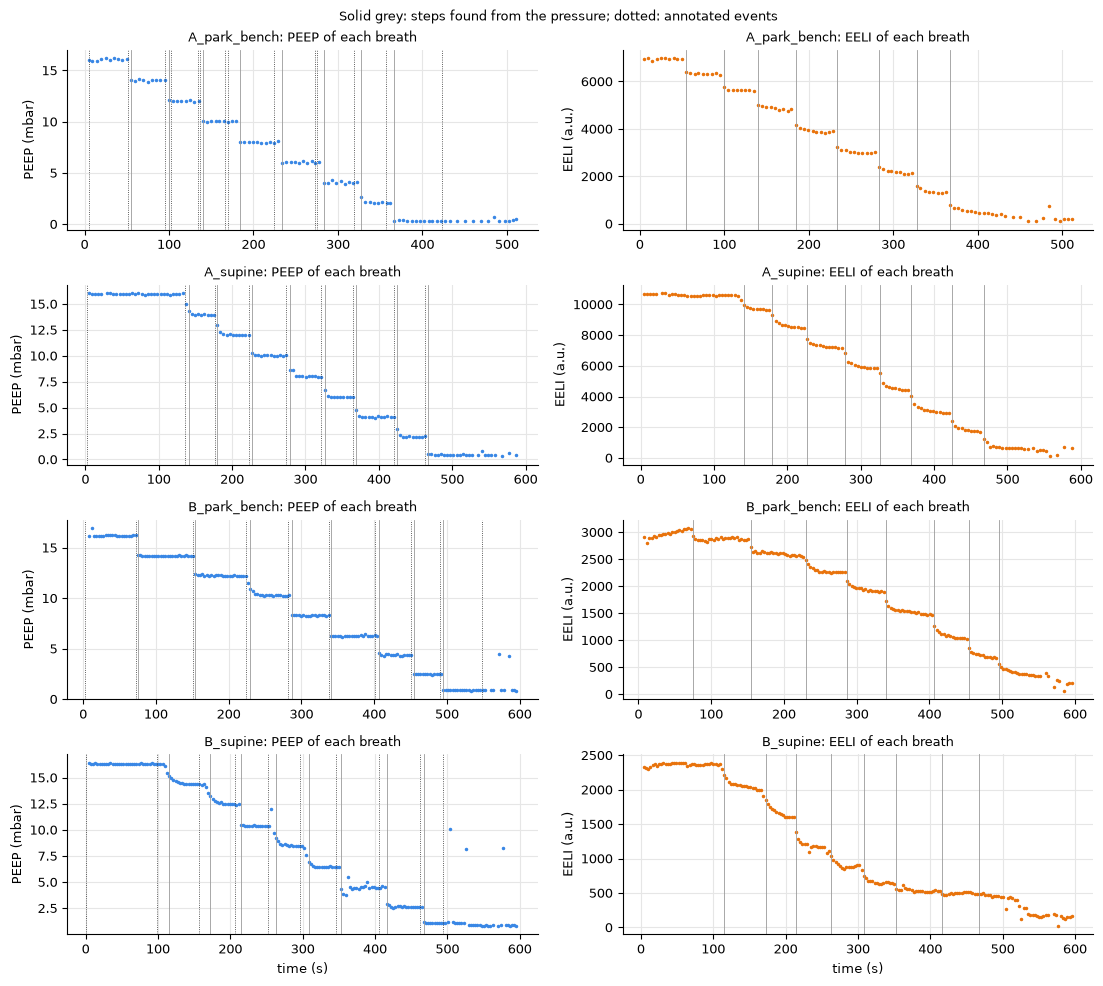

In [9]:
def breath_table(name):
    """Breaths with PEEP, EELI and TIV (global signal, mean of 0.2 s), step and step level."""
    rec = recordings[name]
    b = rec.breaths
    half = int(round(0.1 * rec.fs))
    level = lambda frames: np.array([rec.global_signal[max(0, f - half): f + half + 1].mean() for f in frames])
    table = pd.DataFrame({"time": b.start_time.to_numpy(), "peep": breath_peep(name),
                          "eeli": level(b.start_idx.to_numpy())})
    table["tiv"] = level(b.peak_idx.to_numpy()) - table.eeli
    step_starts = find_steps(table.peep.to_numpy())
    table["step"] = np.searchsorted(step_starts, np.arange(len(table)), side="right") - 1
    table["step_level"] = table.groupby("step").peep.transform("median")
    return table


tables = {name: breath_table(name) for name in recordings}

fig, axes = plt.subplots(4, 2, figsize=(11, 10), sharex="row")
for row, (name, t) in enumerate(tables.items()):
    changes = t.time[t.step.diff() > 0]
    for ax, column, color, label in [(axes[row, 0], "peep", BLUE, "PEEP (mbar)"),
                                     (axes[row, 1], "eeli", ORANGE, "EELI (a.u.)")]:
        ax.plot(t.time, t[column], ".", ms=3, color=color)
        for x in changes:
            ax.axvline(x, color=GREY, lw=0.6)
        ax.set_ylabel(label)
    for x, text in events[name]:
        axes[row, 0].axvline(x, color=INK, lw=0.6, ls=":")
    axes[row, 0].set_title(f"{name}: PEEP of each breath", fontsize=9)
    axes[row, 1].set_title(f"{name}: EELI of each breath", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
fig.suptitle("Solid grey: steps found from the pressure; dotted: annotated events", fontsize=9)
plt.tight_layout()
plt.show()

### Events compared with the steps found

The PEEP changes during the expiration of the last breath at the old level, so I measure how long before the start of
that breath the event was written (negative: written during that breath).

In [10]:
rows = []
for name, t in tables.items():
    first_new = t.index[t.step.diff() > 0]
    for i in first_new:
        change = t.time[i - 1]
        before = [x for x, text in events[name] if change - 30 <= x <= t.time[i]]
        rows.append({"trial": name, "event before the change (s)": round(change - before[-1], 1) if before else np.nan})
pd.DataFrame(rows).groupby("trial")["event before the change (s)"].describe()[["count", "min", "50%", "max"]].round(1)

,count,min,50%,max
trial,,,,
A_park_bench,8.0,-2.0,3.0,9.5
A_supine,8.0,-1.6,-0.2,0.6
B_park_bench,8.0,-0.4,1.0,2.8
B_supine,8.0,1.5,7.2,13.7


Every change has an event. In A supine and B park bench the event was written within a breath of the change
(median about 0-1 s); in B supine from 1.5 to 14 s before it, and in A park bench from 2 s after to 10 s before. So the
events **name** the steps and place them roughly, but the pressure must **cut** them.

### Odd breaths inside a step

Breaths with a PEEP more than 1 mbar away from the level of their step:

In [11]:
pd.concat({name: t.loc[(t.peep - t.step_level).abs() > 1.0, ["time", "peep", "step_level"]]
           for name, t in tables.items()}).round(1)

time  peep  step_level
B_park_bench 175  570.9   4.5         0.9
             178  585.3   4.3         0.9
B_supine     84   256.9  12.0        10.4
             166  504.3  10.1         1.1
             173  526.0   8.2         1.1
             188  577.0   8.2         1.1

Five of the six are the end-expiratory plateaus of the airway closure maneuver at the end of trial B; one
(B supine, 257 s) is a single breath at 12 mbar inside the step at 10.4, cause not determined. The "aop" maneuver of
trial A does not show up here, so this check alone does not find the maneuvers: they are better marked as manual
exclusions with their own label (the user knows when they were done, and they may be analysed on their own).

In B supine, at PEEP 8 and below, the end-expiratory pressure also has small oscillations (more than 0.5 mbar within
the 0.2 s reading in 39 breaths; cardiac oscillations?). The median absorbs them, so they need no flag.

## 4. Can I also measure the plateau and driving pressure of each breath?

Layer 3 will need the compliance of each pixel at each step (Costa method), that is TIV divided by the driving
pressure (plateau - PEEP). These trials were done with an end-inspiratory pause, so the plateau can be read on the same
pressure curve: **the median pressure from 0.25 to 0.05 s before the start of expiration**, where the start of
expiration is the steepest fall of the pressure in the 0.3 s before it comes back within 2 mbar of the next PEEP.
Taking PEEP and plateau from the same channel cancels a constant offset of the sensor.

In [12]:
def plateaus(paw, fs, onsets, peeps, window=(0.25, 0.05)):
    """Plateau of each breath (NaN if no pause is found) and the pressure range inside the reading."""
    p = smooth(paw)
    slope = np.gradient(p) * fs
    plateau, spread = np.full(len(onsets), np.nan), np.full(len(onsets), np.nan)
    for k, (onset, next_onset) in enumerate(zip(onsets[:-1], onsets[1:])):
        peak = onset + np.argmax(paw[onset:next_onset])
        back_to_peep = np.flatnonzero(p[peak:next_onset] < peeps[k + 1] + 2.0)
        if len(back_to_peep) == 0:
            continue
        end = peak + back_to_peep[0]
        lo = max(peak, end - int(0.3 * fs))
        expiration = lo + np.argmin(slope[lo : end + 1])
        a, b = expiration - int(window[0] * fs), expiration - int(window[1] * fs)
        if a > peak:
            plateau[k], spread[k] = np.median(paw[a:b]), np.ptp(paw[a:b])
    return plateau, spread


for name, t in tables.items():
    rec = recordings[name]
    plateau, spread = plateaus(rec.aux.airway_pressure_pod.to_numpy(), rec.fs,
                               readings[name].onset.to_numpy(), t.peep.to_numpy())
    t["plateau"], t["plateau_spread"] = plateau, spread
    t["driving"] = t.plateau - t.peep

pd.DataFrame({
    name: {"plateau found (% of breaths)": round(100 * t.plateau.iloc[:-1].notna().mean()),
           "range inside the reading (mbar, median)": round(t.plateau_spread.median(), 2)}
    for name, t in tables.items()
}).T

,plateau found (% of breaths),"range inside the reading (mbar, median)"
A_park_bench,100.0,0.56
A_supine,99.0,0.45
B_park_bench,100.0,0.81
B_supine,100.0,0.89


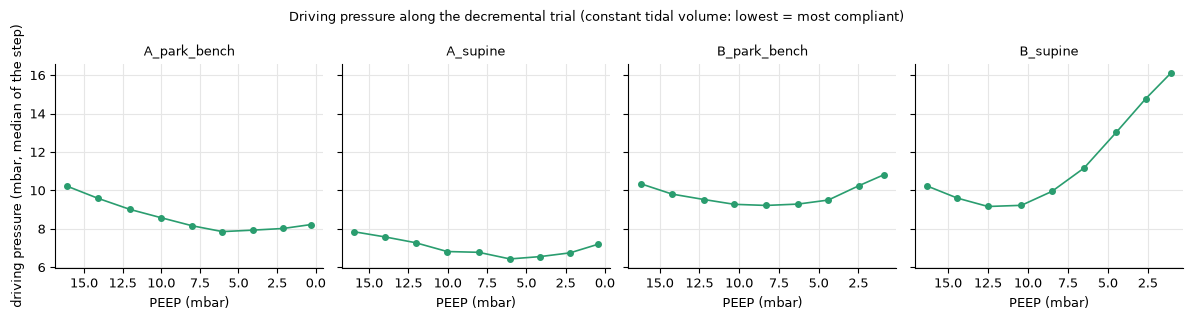

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    by_step = t.groupby("step")[["peep", "driving"]].median()
    ax.plot(by_step.peep, by_step.driving, "o-", color=GREEN, lw=1.2, ms=4)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("PEEP (mbar)")
    ax.invert_xaxis()
axes[0].set_ylabel("driving pressure (mbar, median of the step)")
fig.suptitle("Driving pressure along the decremental trial (constant tidal volume: lowest = most compliant)", fontsize=9)
plt.tight_layout()
plt.show()

A plateau is found in almost every breath, and the driving pressure has a minimum in every trial, as expected
in a decremental trial with constant tidal volume (lowest driving pressure = highest compliance of the respiratory
system). The pressures of each breath are read reliably enough for layer 3.

Limits: without an end-inspiratory pause there is no plateau, and the peak pressure must not be used instead (it
includes the resistive pressure); compliance from the airway pressure is valid only in passive patients.

## 5. How long is the transition after a PEEP change?

After each change EELI moves to a new level, and the breaths of the transition should not be analysed. I looked at
it in two ways, both relative to the tidal variation (TIV), so they do not depend on the units of the image:

- **settling**: the first breath from which EELI stays within 10 % of TIV from the final level of the step (median of
  its last five breaths). In short steps the last five breaths are half of the step, so these times are lower bounds;
- **drift at the end of the step**: the slope of EELI in the last 30 s of the step, robust (Theil-Sen) with its 95 %
  interval, in % of TIV per minute. Step 0 has no change before it, so it is a control.

In [14]:
rows = []
for name, t in tables.items():
    for step, s in t.groupby("step"):
        final, tiv = s.eeli.iloc[-5:].median(), s.tiv.median()
        inside = (s.eeli - final).abs().to_numpy() <= 0.10 * tiv
        settled = next((i for i in range(len(s)) if inside[i:].all()), len(s))
        end = s[s.time >= s.time.iloc[-1] - 30]
        fit = stats.theilslopes(end.eeli, end.time)
        to_pct = 100 * 60 / tiv
        rows.append({"trial": name, "step": step, "peep": round(s.peep.median(), 1),
                     "step length (s)": round(s.time.iloc[-1] - s.time.iloc[0]), "breaths": len(s),
                     "breaths to settle": settled if step > 0 else np.nan,
                     "seconds to settle": (round(s.time.iloc[min(settled, len(s) - 1)] - s.time.iloc[0], 1)
                                           if step > 0 else np.nan),
                     "breaths in last 30 s": len(end),
                     "drift (%TIV/min)": round(fit.slope * to_pct, 1),
                     "drift low": round(fit.low_slope * to_pct, 1), "drift high": round(fit.high_slope * to_pct, 1)})
transitions = pd.DataFrame(rows)
transitions

,trial,step,peep,step length (s),breaths,breaths to settle,seconds to settle,breaths in last 30 s,drift (%TIV/min),drift low,drift high
0,A_park_bench,0,16.1,45,10,NaN,NaN,6,-5.3,-9.6,-0.5
1,A_park_bench,1,14.1,40,9,0.0,0.0,6,-3.8,-16.0,11.0
2,A_park_bench,2,12.0,35,8,0.0,0.0,6,-6.1,-19.4,2.8
3,A_park_bench,3,10.0,39,9,1.0,4.6,7,-12.5,-25.0,1.1
4,A_park_bench,4,8.0,44,10,1.0,4.7,7,-9.6,-17.0,3.7
5,A_park_bench,5,6.0,44,10,1.0,4.7,7,-5.2,-14.5,8.9
6,A_park_bench,6,4.0,39,9,1.0,4.7,7,-13.5,-20.4,-0.4
7,A_park_bench,7,2.1,35,8,1.0,4.5,7,-15.6,-34.4,-1.2
8,A_park_bench,8,0.3,144,25,20.0,124.2,6,-2.2,-150.0,29.4
9,A_supine,0,16.0,132,31,NaN,NaN,7,-7.6,-48.6,2.1


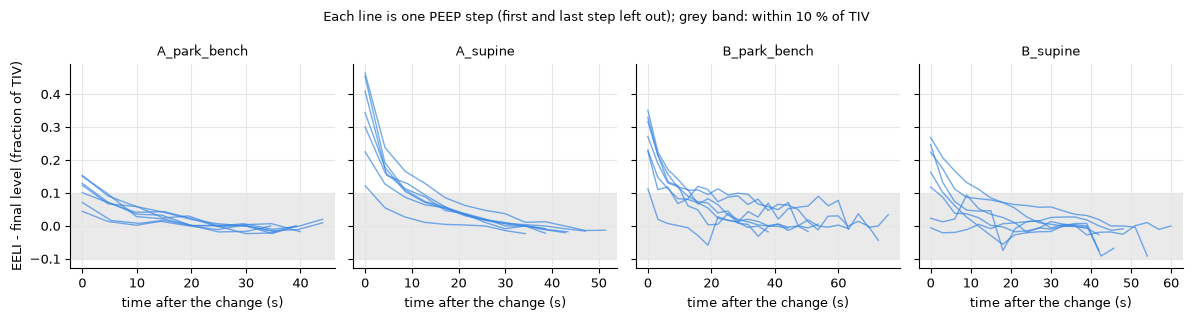

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    for step, s in t.groupby("step"):
        if step == 0 or step == t.step.max():
            continue
        final, tiv = s.eeli.iloc[-5:].median(), s.tiv.median()
        ax.plot(s.time - s.time.iloc[0], (s.eeli - final) / tiv, color=BLUE, lw=1, alpha=0.7)
    ax.axhspan(-0.1, 0.1, color=GREY, alpha=0.2, lw=0)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("time after the change (s)")
axes[0].set_ylabel("EELI - final level (fraction of TIV)")
fig.suptitle("Each line is one PEEP step (first and last step left out); grey band: within 10 % of TIV", fontsize=9)
plt.tight_layout()
plt.show()

In [16]:
middle = transitions[(transitions.step > 0)
                     & (transitions.step < transitions.groupby("trial").step.transform("max"))]
summary = middle.groupby("trial").agg(
    settle_median_s=("seconds to settle", "median"), settle_max_s=("seconds to settle", "max"),
    never_settled=("breaths to settle", lambda x: int((x == middle.loc[x.index, "breaths"]).sum())),
    breaths_last_30s=("breaths in last 30 s", lambda x: f"{x.min()}-{x.max()}"),
    negative_drifts=("drift (%TIV/min)", lambda x: f"{(x < 0).sum()}/{len(x)}"),
    drift_min=("drift (%TIV/min)", "min"), drift_max=("drift (%TIV/min)", "max"),
)
control = transitions[transitions.step == 0].set_index("trial")[["drift (%TIV/min)", "drift low", "drift high"]]
summary.join(control.add_prefix("step 0 ")).round(1)

,settle_median_s,settle_max_s,never_settled,breaths_last_30s,negative_drifts,drift_min,drift_max,step 0 drift (%TIV/min),step 0 drift low,step 0 drift high
trial,,,,,,,,,,
A_park_bench,4.6,4.7,0,6-7,7/7,-15.6,-3.8,-5.3,-9.6,-0.5
A_supine,12.8,17.1,0,7-8,7/7,-26.1,-9.8,-7.6,-48.6,2.1
B_park_bench,12.6,25.3,0,10-10,7/7,-22.6,-2.6,27.2,18.7,36.3
B_supine,5.9,15.0,0,10-11,5/7,-29.7,9.4,-0.3,-9.6,6.1


Leaving out the first and the last step (PEEP 0, which contains the maneuvers), EELI comes within 10 % of TIV
from its final level within 25 s of the change in every step (lower bounds, see above). But it does not stop there:
in the last 30 s EELI is still falling in 26 of 28 steps, by up to about 30 % of TIV per minute.

The cause is not determined: in step 0, before any change, EELI already drifts in two of the four trials (A park bench
-5, B park bench +27 % of TIV per minute; see the control columns), and in B supine the decline is largest at the high
PEEP steps, not at the low ones as derecruitment would suggest. With two
patients I cannot separate derecruitment, slow relaxation of the lung and chest wall, and a drift of the image.

The transition is different from step to step, so a fixed number of breaths would be either too short or too long,
and a settling rule depends on a final level that is itself still moving. A simpler rule is to keep the last 30 s of each
step: here it leaves 6 to 11 breaths per step, and the drift in that window (with its interval) can be reported with
the step, so a step that is still moving is visible instead of hidden. These steps are short (34-76 s); with longer
steps the window should not grow beyond half of the step.

## 6. Without a pressure signal, can I find the steps from EELI?

When there is no pressure (no PressurePod, no Medibus), the only trace of a PEEP change is the fall of EELI. I tried
the simplest rule: a change where EELI falls by more than a fraction of TIV within three breaths. The steps found
from the pressure are the reference.

In [17]:
def eeli_changes(eeli, tiv, fraction, span=3, min_gap=5):
    """First breath of each fall of EELI larger than `fraction` x median TIV within `span` breaths."""
    drop = eeli[:-span] - eeli[span:]
    found = []
    for i in np.flatnonzero(drop > fraction * np.median(tiv)):
        if not found or i - found[-1] >= min_gap:
            found.append(i)
    return np.array(found) + 1


rows = []
for fraction in (0.2, 0.3, 0.5):
    hits = false = total = 0
    for name, t in tables.items():
        truth = t.index[t.step.diff() > 0].to_numpy()
        found = eeli_changes(t.eeli.to_numpy(), t.tiv.to_numpy(), fraction)
        matched = {f for f in found if np.min(np.abs(truth - f)) <= 3}
        hits += sum(np.min(np.abs(found - x)) <= 3 for x in truth) if len(found) else 0
        false += len(found) - len(matched)
        total += len(truth)
    rows.append({"fall larger than (x TIV)": fraction, "changes found": f"{hits}/{total}", "false changes": false})
pd.DataFrame(rows).set_index("fall larger than (x TIV)")

,changes found,false changes
fall larger than (x TIV),,
0.2,28/32,4
0.3,22/32,1
0.5,0/32,0


No threshold finds all the changes without false ones, and the threshold was chosen on the same changes it is
scored on. Within three breaths the fall of EELI at a 2 mbar step is never larger than half a tidal breath here, and it
is spread over several breaths. On these recordings EELI alone is not enough to find the steps. A later option is
semi-automatic: start from the event typed by the user, move it to the steepest fall of EELI nearby, and ask the user
to confirm.

## 7. Decisions

Proposals from this notebook, to confirm:

1. **Source of the PEEP**: the airway pressure (PressurePod, Medibus waveform or Timpel `airway_pressure`, in this
   order); the Medibus `peep` value if there is no waveform. Never mixed within a breath. The event texts are not used
   to cut the steps.
2. **Pressures of a breath**, all from the same channel:
   - start of inspiration on the pressure: last minimum before the steepest rise near the start of the EIT breath;
   - PEEP: median pressure in the 0.2 s before it;
   - plateau: median pressure from 0.25 to 0.05 s before the start of expiration (NaN if there is no pause);
   - driving pressure = plateau - PEEP.
3. **Steps**: a new step when three breaths in a row are more than a threshold away from the current level and within
   1 mbar of each other; threshold = half of the step of the protocol (1 mbar by default); level = median PEEP.
4. **Transition**: the breaths before the last 30 s of each step are `in_transition` (window at most half of the step,
   at least 3 breaths); the EELI drift in that window is reported with the step, with its 95 % interval.
5. **Maneuvers** (airway closure, aop): manual exclusions with their own label.
6. **No pressure signal**: no automatic steps for now.

Limits: four trials from two patients, decremental only, volume control with an end-inspiratory pause, PressurePod
only, Timpel pressure not tested; the PEEP read at the airway opening does not include intrinsic PEEP; compliance from
the airway pressure is valid only in passive patients.